# PV End of Service Estimates for IEA PVPS and EPRI
This journal is the math for PV ICE end of service quantities estimates for multiple publications, including an EPRI rate of recycling report and an IEA PVPS report. 

Deployment (historical and future):
- IEA PVPS Task 1 for historical PV deployment by country, most recent is published Nov 2026
- LBNL utility scale PV report for CdTe installs in the U.S., plus Wood Mackenzie sector-wise installs to create a %CdTe
- 

Scenarios include: 
- PV fleets degradation, by PVCZ [Karin et al 2020] "PVCZdeg"
- IRENA early loss, regular loss, "IRENAearly", "IRENAreg"
- PV Fleets median degradation, "DegMedian"

In [1]:
import numpy as np
import pandas as pd
import os,sys
from pathlib import Path
import matplotlib.pyplot as plt
import re

plt.rcParams.update({'font.size': 18})
plt.rcParams['figure.figsize'] = (10, 6)

cwd = os.getcwd() #grabs current working directory

testfolder = cwd #str(Path().resolve().parent.parent / 'PV_ICE' / 'TEMP' / 'PVPS_EoSEstimates_Nov2026')
#inputfolder = str(Path().resolve().parent.parent / 'PV_ICE' / 'TEMP')
baselinesfolder = str(Path().resolve().parent.parent /'PV_ICE' / 'baselines')
supportMatfolder = str(Path().resolve().parent.parent / 'PV_ICE' / 'baselines' / 'SupportingMaterial')

if not os.path.exists(testfolder):
    os.makedirs(testfolder)

In [2]:
#load in a baseline and materials for modification
import PV_ICE

PV_ICE.__version__

'0.4.3'

In [3]:
#pull in files needed for the multiple scenario runs
scennames = ['test'] #['PVCZdeg'] #"IRENAearly", "IRENAreg", "DegMedian"
countries = ['FRANCE','SPAIN','GERMANY','ITALY','NETHERLANDS'] #'USA',

MATERIALS = ['glass','silver','silicon', 'copper', 'aluminium_frames', 'encapsulant', 'backsheet']
MATERIALS_CdTe = ['cadmium', 'tellurium', 'glass_cdte', 'aluminium_frames_cdte', 'encapsulant_cdte', 'copper_cdte']
moduleFile_m_Si = os.path.join(baselinesfolder, 'baseline_modules_mass_World.csv')
moduleFile_m_CdTe = os.path.join(baselinesfolder, 'baseline_modules_mass_US_CdTe.csv')

#### Prep the files

In [4]:
deploy_CdTe_pct = pd.read_csv(os.path.join(baselinesfolder, 'baseline_deploy_SivsTF_marketshare_allsector.csv'), index_col='year')
deployment_bycountry_raw = pd.read_csv(os.path.join(testfolder, 'IEAPVPS-Task1-GlobalInstallsbyCountry_MWdc.csv'), index_col='Year')
PVCZ_deg_rates = pd.read_csv(os.path.join(testfolder, 'PVFleetsDeg_byPVCZ.csv'))

In [5]:
deployment_bycountry_raw.head(4)

,AUSTRALIA,AUSTRIA,BELGIUM,CANADA,CHINA,DENMARK,FINLAND,FRANCE,GERMANY,INDIA,...,THAILAND,TÜRKIYE,UK,USA,REST OF EU COUNTRIES,TOTAL IEA PVPS,BRAZIL,PAKISTAN,TOTAL NON IEA PVPS,TOTAL
Year,,,,,,,,,,,,,,,,,,,,,
1992,7,1,0,1,0,0,0,2,6,0,...,0,0,0,0,0,50,0,0,0,50
1993,2,0,0,0,0,0,0,0,3,0,...,0,0,0,0,0,16,0,0,0,16
1994,2,0,0,0,0,0,0,0,3,0,...,0,0,0,0,0,16,0,0,9,25
1995,2,0,0,0,0,0,0,1,6,0,...,0,0,0,0,0,24,0,0,0,25


In [6]:
deploy_CdTe_pct.head(4)

,% CdTe,%Silicon
year,,
1995,0.0,100.0
1996,0.0,100.0
1997,0.0,100.0
1998,0.0,100.0


In [7]:
PVCZ_deg_rates.head(4)

,Years before reaching 80%,Degradation Rate,USA PV Fleets,USA PV Fleets (H method),France (T3:T4),Italy (T4:T5),Spain (T4:T5:T6),Germany (T3),Netherlands (T3)
0,100,-0.01,0.00,9.06,9.520,7.050,8.15,10.34,10.34
1,100,-0.20,18.42,12.71,12.735,9.720,11.61,15.38,15.38
2,50,-0.40,10.06,15.26,14.550,15.895,15.40,14.40,14.40
3,33,-0.60,12.30,14.19,12.705,15.785,14.65,12.37,12.37


Let's start simple, run all the countries with 0.7% deg

In [8]:
baselinesfolder

'C:\\Users\\hmirletz\\Documents\\GitHub\\PV_ICE\\PV_ICE\\baselines'

In [9]:
sim1 = PV_ICE.Simulation(name='sim1', path=testfolder)
for scen in countries:
    sim1.createScenario(name=scen, massmodulefile=moduleFile_m_Si)
    for mat in range (0, len(MATERIALS)):
        matbaseline_m = os.path.join(baselinesfolder,'baseline_material_mass_'+MATERIALS[mat]+'.csv')
        #matbaseline_e = os.path.join(baselinesfolder,'baseline_material_energy_'+MATERIALS[mat]+'.csv')
        sim1.scenario[scen].addMaterial(MATERIALS[mat], massmatfile=matbaseline_m)#, energymatfile=matbaseline_e)

path = C:\Users\hmirletz\Documents\GitHub\PV_ICE\Studies\PVPS_EoSEstimates_Nov2026
Baseline folder directed to default:  C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\baselines
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']


In [10]:
#simulation wide modficiations
sim1.scenMod_noCircularity()
sim1.trim_Years(startYear=1995, endYear=2025) #dont yet need projection into the future, only looking at waste in 2023, 2024, 2025

Trimming and extending  FRANCE
No energy data loaded. Skipping for all next scenarios and materials
FRANCE backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  SPAIN
SPAIN backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  GERMANY
GERMANY backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  ITALY
ITALY backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  NETHERLANDS
NETHERLANDS backsheet : Data trimmed for Mass, years now encompass  1995  to  2025


In [11]:
sim1.scenario.keys()

dict_keys(['FRANCE', 'SPAIN', 'GERMANY', 'ITALY', 'NETHERLANDS'])

In [12]:
for scen in countries:
    sim1.modifyScenario(scen, 'new_Installed_Capacity_[MW]', 0.0, start_year=1995) #deployment_bycountry_raw.loc[1995:,scen]
    sim1.modifyScenario(scen, 'new_Installed_Capacity_[MW]', deployment_bycountry_raw.loc[1995:,scen], start_year=1995)

In [38]:
sim1.scenario['GERMANY'].dataIn_m.tail()

,year,new_Installed_Capacity_[MW],mod_eff,mod_reliability_t50,mod_reliability_t90,mod_degradation,mod_lifetime,mod_MFG_eff,mod_Repair,mod_MerchantTail,...,mod_EOL_pg1_landfill,mod_EOL_pg2_stored,mod_EOL_pg3_reMFG,mod_EOL_pg4_recycled,mod_EOL_reMFG_yield,mod_EOL_sp_reMFG_recycle,mod_EOL_pb1_landfill,mod_EOL_pb2_stored,mod_EOL_pb3_reMFG,mod_EOL_pb4_recycled
26,2021,5712.0,20.900000,39.0,42.0,0.75,35.0,98,0.0,0.0,...,100.0,0.0,0.0,0.0,0,0.0,100.0,0.0,0.0,0.0
27,2022,7558.0,21.100000,39.0,42.0,0.60,35.0,98,0.0,0.0,...,100.0,0.0,0.0,0.0,0,0.0,100.0,0.0,0.0,0.0
28,2023,15332.0,21.860752,39.0,42.0,0.60,35.0,98,0.0,0.0,...,100.0,0.0,0.0,0.0,0,0.0,100.0,0.0,0.0,0.0
29,2024,17220.0,22.318415,39.0,42.0,0.60,35.0,98,0.0,0.0,...,100.0,0.0,0.0,0.0,0,0.0,100.0,0.0,0.0,0.0
30,2025,17600.0,22.648932,39.0,42.0,0.60,35.0,98,0.0,0.0,...,100.0,0.0,0.0,0.0,0,0.0,100.0,0.0,0.0,0.0


(0.0, 18480.0)

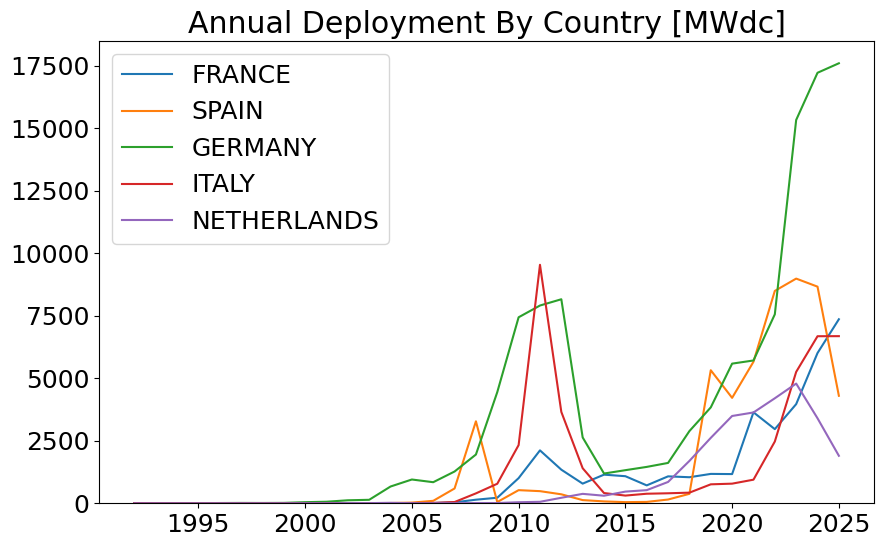

In [45]:
for scen in countries:
    plt.plot(deployment_bycountry_raw.loc[:,scen])

plt.legend(countries)
plt.title('Annual Deployment By Country [MWdc]')
plt.ylim(0,)

In [ ]:
#Lifetime and Degradation
#values taken from lifetime vs recycling paper
#degradation rate:
#sim1.modifyScenario('test', 'mod_degradation',0.2, start_year=2000) 
#sim1.modifyScenario('test', 'mod_lifetime', 50, start_year=2000) 
#sim1.modifyScenario('test', 'new_Installed_Capacity_[MW]', 0.0, start_year=1995) 
#sim1.modifyScenario('test', 'mod_eff', 17.0, start_year=1995) 

#sim1.scenMod_perfectRecycling()
#sim1.scenMod_noCircularity()

In [17]:
sim1.calculateMassFlow()

>>>> Calculating Material Flows <<<<

Working on Scenario:  FRANCE
********************
Finished Area+Power Generation Calculations
==> Working on Material :  glass
==> Working on Material :  silver
==> Working on Material :  silicon
==> Working on Material :  copper
==> Working on Material :  aluminium_frames
==> Working on Material :  encapsulant
==> Working on Material :  backsheet
Working on Scenario:  SPAIN
********************
Finished Area+Power Generation Calculations
==> Working on Material :  glass
==> Working on Material :  silver
==> Working on Material :  silicon
==> Working on Material :  copper
==> Working on Material :  aluminium_frames
==> Working on Material :  encapsulant
==> Working on Material :  backsheet
Working on Scenario:  GERMANY
********************
Finished Area+Power Generation Calculations
==> Working on Material :  glass
==> Working on Material :  silver
==> Working on Material :  silicon
==> Working on Material :  copper
==> Working on Material :  alumi

In [18]:
sim1.scenario['FRANCE'].dataOut_m.keys()

Index(['Area', 'Cumulative_Active_Area', 'EOL_BadStatus', 'EOL_Landfill0',
       'EOL_PATHS', 'EOL_PG', 'Effective_Capacity_[W]', 'Landfill_0_ProjLife',
       'MerchantTail_Area', 'MerchantTail_[W]', 'ModuleTotal_MFG', 'P2_stored',
       'P3_reMFG', 'P4_recycled', 'PB1_landfill', 'PB2_stored', 'PB3_reMFG',
       'PB3_reMFG_unyield', 'PB3_reMFG_yield', 'PB4_recycled', 'PG1_landfill',
       'PG2_stored', 'PG3_reMFG', 'PG3_reMFG_unyield', 'PG3_reMFG_yield',
       'PG4_recycled', 'Power_Degraded_[W]', 'Repaired_Area', 'Repaired_[W]',
       'Resold_Area', 'Resold_[W]', 'WeibullParams',
       'Yearly_Sum_Area_EOLby_Degradation', 'Yearly_Sum_Area_EOLby_Failure',
       'Yearly_Sum_Area_EOLby_ProjectLifetime', 'Yearly_Sum_Area_PathsBad',
       'Yearly_Sum_Area_PathsGood', 'Yearly_Sum_Area_atEOL',
       'Yearly_Sum_Power_EOLby_Degradation', 'Yearly_Sum_Power_EOLby_Failure',
       'Yearly_Sum_Power_EOLby_ProjectLifetime', 'Yearly_Sum_Power_PathsBad',
       'Yearly_Sum_Power_PathsGood

Text(0.5, 1.0, 'Cumulative Effective capacity [GWdc]')

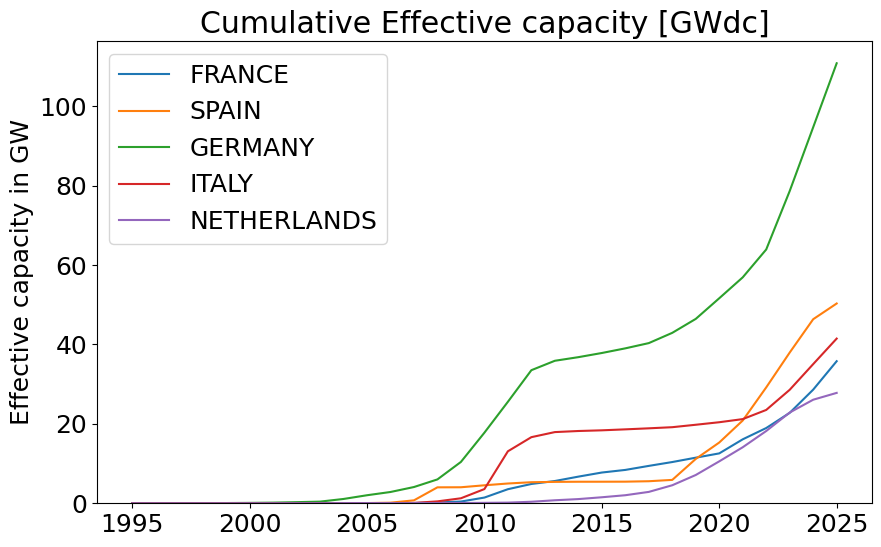

In [48]:
for scen in countries:
    plt.plot(sim1.scenario[scen].dataIn_m['year'], sim1.scenario[scen].dataOut_m['Effective_Capacity_[W]']/1e9)
plt.ylim(0,)
plt.legend(countries)
plt.ylabel('Effective capacity in GW')
plt.title('Cumulative Effective capacity [GWdc]')
#plt.plot(sim1.scenario['base'].dataIn_m['new_Installed_Capacity_[MW]'])

In [20]:
sim1_annual, sim1_cumu = sim1.aggregateResults()

C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:2164: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  USyearly[nicekey+'_'+mat+'_'+self.name+'_'+scen] = self.scenario[scen].material[mat].matdataOut_m[keywd]
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:2164: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  USyearly[nicekey+'_'+mat+'_'+self.name+'_'+scen] = self.scenario[scen].material[mat].matdataOut_m[keywd]
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\mai

In [21]:
sim1_cumu.keys()

Index(['VirginStock_glass_sim1_FRANCE_[Tonnes]',
       'VirginStock_silver_sim1_FRANCE_[Tonnes]',
       'VirginStock_silicon_sim1_FRANCE_[Tonnes]',
       'VirginStock_copper_sim1_FRANCE_[Tonnes]',
       'VirginStock_aluminium_frames_sim1_FRANCE_[Tonnes]',
       'VirginStock_encapsulant_sim1_FRANCE_[Tonnes]',
       'VirginStock_backsheet_sim1_FRANCE_[Tonnes]',
       'VirginStock_Module_sim1_FRANCE_[Tonnes]',
       'WasteAll_glass_sim1_FRANCE_[Tonnes]',
       'WasteAll_silver_sim1_FRANCE_[Tonnes]',
       ...
       'WasteMFG_copper_sim1_NETHERLANDS_[Tonnes]',
       'WasteMFG_aluminium_frames_sim1_NETHERLANDS_[Tonnes]',
       'WasteMFG_encapsulant_sim1_NETHERLANDS_[Tonnes]',
       'WasteMFG_backsheet_sim1_NETHERLANDS_[Tonnes]',
       'WasteMFG_Module_sim1_NETHERLANDS_[Tonnes]',
       'newInstalledCapacity_sim1_FRANCE_[MW]',
       'newInstalledCapacity_sim1_SPAIN_[MW]',
       'newInstalledCapacity_sim1_GERMANY_[MW]',
       'newInstalledCapacity_sim1_ITALY_[MW]',
       'n

In [22]:
#MASS
sim1_cumu.filter(like='WasteEOL')

,WasteEOL_glass_sim1_FRANCE_[Tonnes],WasteEOL_silver_sim1_FRANCE_[Tonnes],WasteEOL_silicon_sim1_FRANCE_[Tonnes],WasteEOL_copper_sim1_FRANCE_[Tonnes],WasteEOL_aluminium_frames_sim1_FRANCE_[Tonnes],WasteEOL_encapsulant_sim1_FRANCE_[Tonnes],WasteEOL_backsheet_sim1_FRANCE_[Tonnes],WasteEOL_Module_sim1_FRANCE_[Tonnes],WasteEOL_glass_sim1_SPAIN_[Tonnes],WasteEOL_silver_sim1_SPAIN_[Tonnes],...,WasteEOL_backsheet_sim1_ITALY_[Tonnes],WasteEOL_Module_sim1_ITALY_[Tonnes],WasteEOL_glass_sim1_NETHERLANDS_[Tonnes],WasteEOL_silver_sim1_NETHERLANDS_[Tonnes],WasteEOL_silicon_sim1_NETHERLANDS_[Tonnes],WasteEOL_copper_sim1_NETHERLANDS_[Tonnes],WasteEOL_aluminium_frames_sim1_NETHERLANDS_[Tonnes],WasteEOL_encapsulant_sim1_NETHERLANDS_[Tonnes],WasteEOL_backsheet_sim1_NETHERLANDS_[Tonnes],WasteEOL_Module_sim1_NETHERLANDS_[Tonnes]
year,,,,,,,,,,,,,,,,,,,,,
1995,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,...,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1996,0.000214,0.000002,0.000023,1.440025e-07,0.000083,0.000023,0.000005,0.000350,0.000000e+00,0.000000e+00,...,0.000010,0.000700,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1997,0.004993,0.000055,0.000529,3.355011e-06,0.001925,0.000528,0.000113,0.008145,0.000000e+00,0.000000e+00,...,0.000206,0.014922,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1998,0.036371,0.000396,0.003839,2.444112e-05,0.013971,0.003846,0.000826,0.059272,0.000000e+00,0.000000e+00,...,0.001232,0.089367,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1999,0.151310,0.001641,0.015935,1.016802e-04,0.057969,0.016001,0.003448,0.246406,0.000000e+00,0.000000e+00,...,0.004384,0.318070,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2000,0.452374,0.004894,0.047577,3.039956e-04,0.173028,0.047839,0.010334,0.736350,0.000000e+00,0.000000e+00,...,0.011727,0.850766,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2001,1.094331,0.011818,0.114990,7.353905e-04,0.418117,0.115726,0.025038,1.780755,0.000000e+00,0.000000e+00,...,0.026161,1.897969,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2002,2.287503,0.024672,0.240216,1.537202e-03,0.873332,0.241903,0.052396,3.721560,0.000000e+00,0.000000e+00,...,0.051439,3.731855,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2003,4.296778,0.046300,0.451004,2.887435e-03,1.639500,0.454384,0.098501,6.989355,0.000000e+00,0.000000e+00,...,0.092087,6.680899,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


In [24]:
eol_module_tonnes = sim1_cumu.filter(like='WasteEOL_Module')
eol_module_tonnes

,WasteEOL_Module_sim1_FRANCE_[Tonnes],WasteEOL_Module_sim1_SPAIN_[Tonnes],WasteEOL_Module_sim1_GERMANY_[Tonnes],WasteEOL_Module_sim1_ITALY_[Tonnes],WasteEOL_Module_sim1_NETHERLANDS_[Tonnes]
year,,,,,
1995,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00
1996,0.000350,0.000000e+00,0.002099,0.000700,0.000000e+00
1997,0.008145,0.000000e+00,0.048187,0.014922,0.000000e+00
1998,0.059272,0.000000e+00,0.341045,0.089367,0.000000e+00
1999,0.246406,0.000000e+00,1.391063,0.318070,0.000000e+00
2000,0.736350,0.000000e+00,4.107131,0.850766,0.000000e+00
2001,1.780755,0.000000e+00,9.852769,1.897969,0.000000e+00
2002,3.721560,0.000000e+00,20.473839,3.731855,0.000000e+00
2003,6.989355,0.000000e+00,38.288154,6.680899,0.000000e+00


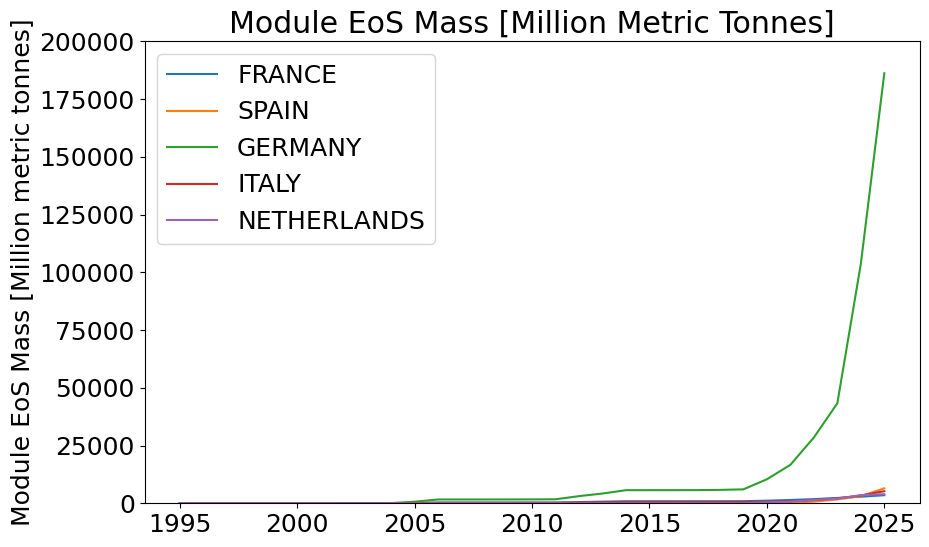

In [82]:
plt.plot(eol_module_tonnes)
plt.ylim(0,200000)
plt.title('Module EoS Mass [Million Metric Tonnes]')
plt.ylabel('Module EoS Mass [Million metric tonnes]')
plt.legend(countries)

# PV Fleets Degradation by PV Climate Zone

create baseline input files for PV Fleets degradation spread for each country. Do as separate simulation, just in case.

In [25]:
#fleets_deg_rates = pd.read_csv(os.path.join(supportMatfolder, 'PVFleets_Degradation_Data.csv'))
PVCZ_deg_rates
#df_baseline_module_world = pd.read_csv(moduleFile_m)


,Years before reaching 80%,Degradation Rate,USA PV Fleets,USA PV Fleets (H method),France (T3:T4),Italy (T4:T5),Spain (T4:T5:T6),Germany (T3),Netherlands (T3)
0,100,-0.01,0.00,9.06,9.520,7.050,8.15,10.34,10.34
1,100,-0.20,18.42,12.71,12.735,9.720,11.61,15.38,15.38
2,50,-0.40,10.06,15.26,14.550,15.895,15.40,14.40,14.40
3,33,-0.60,12.30,14.19,12.705,15.785,14.65,12.37,12.37
4,25,-0.80,11.62,11.93,10.250,14.585,13.37,10.93,10.93
5,20,-1.00,10.22,9.15,9.220,9.365,9.14,8.70,8.70
6,16,-1.20,8.51,7.61,7.675,8.540,8.11,7.26,7.26
7,14,-1.40,6.90,4.43,4.885,5.025,4.64,3.86,3.86
8,12,-1.60,5.37,4.08,4.820,4.125,3.99,3.73,3.73
9,11,-1.80,4.70,2.95,3.290,3.085,2.97,2.75,2.75


### Create the module files to read in for each country and each degradation cohort within the country
This section is just manipulating and creating csvs

In [28]:
deg_baselines_filenames = [] # for later use
deg_rate_log = [] #for later use
country_deg_rate_log = [] # for later use

df_baseline_module_world = pd.DataFrame(pd.read_csv(moduleFile_m_Si)) #create a template to copy

for country in countries:
    #prep the total country deployment for multiplication later
    country_deploy_total = deployment_bycountry_raw.loc[1995:,country] #extract the country total deployment from PVPS file
    df_module_country = df_baseline_module_world.copy() #make copy of the world df for the country
    df_module_country.loc[1:,'new_Installed_Capacity_[MW]'] = 0.0 #wipe the install
    df_module_country.loc[1:len(country_deploy_total),'new_Installed_Capacity_[MW]'] = country_deploy_total.values #overwrite with country data

    country_pvcz_cohort = PVCZ_deg_rates.filter(regex=re.compile(country, re.IGNORECASE)) #select the country specific cohort:deg rate column
    deg_col = PVCZ_deg_rates['Degradation Rate']
    pvcz_country_deg_cohort = pd.concat([deg_col,country_pvcz_cohort], axis=1) #attach cohort to the degradation rate
    
    for row in pvcz_country_deg_cohort.index:
        df_module_country_cohort = df_module_country.copy() #make copy df of country specific deployment
        
        deg_rate = pvcz_country_deg_cohort.loc[row]['Degradation Rate']*-1 #extract deg rate, already negative, needs to be positive in final file
        cohort_percent = pvcz_country_deg_cohort.iloc[row,1]/100 #extract fraction for cohort
        deg_rate_log.append(deg_rate) #for later use
        country_deg_rate_log.append(country) #for later use
    
        #modify the cohort deployment, fix label
        cohort_deploy = pd.to_numeric(df_module_country.loc[1:,'new_Installed_Capacity_[MW]'], errors='coerce')*cohort_percent 
        df_module_country_cohort['new_Installed_Capacity_[MW]'] = cohort_deploy
        #df_module_country_cohort.loc[1:,'new_Installed_Capacity_[MW]'] = 'MW'
    
        #modify deg rate
        df_module_country_cohort.loc[1:,'mod_degradation'] = deg_rate
        
        #save out a file for each deg rate cohort
        out_name = f"baseline_modules_mass_{country}_deg_{abs(deg_rate):0.1f}.csv"
        #later_scen_name = 
        out_path = os.path.join(testfolder, 'input', country) #save to the study folder
        if not os.path.exists(out_path):
            os.makedirs(out_path)
        deg_baselines_filenames.append(out_name) #later use, internal to python record
        df_module_country_cohort.to_csv(os.path.join(out_path, out_name), index=False)


In [29]:
#prep list of files as a series-->DF that can be called/iterated
deg_baselines_filenames_series = pd.Series(deg_baselines_filenames)
deg_rate_log_series = pd.Series(deg_rate_log)
country_deg_rate_log_series = pd.Series(country_deg_rate_log)

df_DegRate_FilePath= pd.concat([deg_rate_log_series, country_deg_rate_log_series, deg_baselines_filenames_series], axis=1)


In [33]:
df_DegRate_FilePath

,0,1,2
0,0.01,FRANCE,baseline_modules_mass_FRANCE_deg_0.0.csv
1,0.20,FRANCE,baseline_modules_mass_FRANCE_deg_0.2.csv
2,0.40,FRANCE,baseline_modules_mass_FRANCE_deg_0.4.csv
3,0.60,FRANCE,baseline_modules_mass_FRANCE_deg_0.6.csv
4,0.80,FRANCE,baseline_modules_mass_FRANCE_deg_0.8.csv
...,...,...,...
150,5.20,NETHERLANDS,baseline_modules_mass_NETHERLANDS_deg_5.2.csv
151,5.40,NETHERLANDS,baseline_modules_mass_NETHERLANDS_deg_5.4.csv
152,5.60,NETHERLANDS,baseline_modules_mass_NETHERLANDS_deg_5.6.csv
153,5.80,NETHERLANDS,baseline_modules_mass_NETHERLANDS_deg_5.8.csv


## Create scenarios in a sim2 from the newly created files
Create a scenario for each country and deg rate cohort. Currently this set of scenarios excludes the US due to the CdTe complication

In [35]:
# create a scenario for each country and degradation rate, using the log from creating the csvs
#currently excluding US due to CdTe complications
sim2 = PV_ICE.Simulation(name='PVCZ_noUSA', path=testfolder)

for row in df_DegRate_FilePath.index:
    file_country = df_DegRate_FilePath.loc[row][1]
    scen_country_deg = f"{str(df_DegRate_FilePath.loc[row][1])}_{df_DegRate_FilePath.loc[row][0]}" #create name from df log
    filepath = os.path.join("input", file_country, df_DegRate_FilePath.loc[row][2]) #pull filepath from df log
    
    sim2.createScenario(name=scen_country_deg, massmodulefile=filepath)
    sim2.scenario[scen_country_deg].addMaterials(['glass', 'silicon', 'silver', 'copper', 'aluminium_frames', 'encapsulant', 'backsheet'])

path = C:\Users\hmirletz\Documents\GitHub\PV_ICE\Studies\PVPS_EoSEstimates_Nov2026
Baseline folder directed to default:  C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\baselines
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']
Adding Mass AND Energy files for:  glass
Adding Mass AND Energy files for:  silicon
Adding Mass AND Energy files for:  silver
Adding Mass AND Energy files for:  copper
Adding Mass AND Energy files for:  aluminium_frames
Adding Mass AND Energy files for:  encapsulant
Adding Mass AND Energy files for:  backsheet
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']
Adding Mass AND Energy files for:  glass
Adding Mass AND Energy files for:  silicon
Adding Mass AND Energy files for:  silver
Adding Mass AND Energy files for:  copper
Adding Mass AND Energy files for:  aluminium_frames
Adding Mass AND Energy files for:  encapsulant
Add

In [37]:
#simulation wide modficiations
sim2.scenMod_noCircularity()
sim2.trim_Years(startYear=1995, endYear=2025) #dont yet need projection into the future, only looking at waste in 2023, 2024, 2025

Trimming and extending  FRANCE_0.01
No energy data loaded. Skipping for all next scenarios and materials
FRANCE_0.01 backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  FRANCE_0.2
FRANCE_0.2 backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  FRANCE_0.4
FRANCE_0.4 backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  FRANCE_0.6
FRANCE_0.6 backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  FRANCE_0.8
FRANCE_0.8 backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  FRANCE_1.0
FRANCE_1.0 backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  FRANCE_1.2
FRANCE_1.2 backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  FRANCE_1.4
FRANCE_1.4 backsheet : Data trimmed for Mass, years now encompass  1995  to

In [36]:
sim2.scenario.keys()

dict_keys(['FRANCE_0.01', 'FRANCE_0.2', 'FRANCE_0.4', 'FRANCE_0.6', 'FRANCE_0.8', 'FRANCE_1.0', 'FRANCE_1.2', 'FRANCE_1.4', 'FRANCE_1.6', 'FRANCE_1.8', 'FRANCE_2.0', 'FRANCE_2.2', 'FRANCE_2.4', 'FRANCE_2.6', 'FRANCE_2.8', 'FRANCE_3.0', 'FRANCE_3.2', 'FRANCE_3.4', 'FRANCE_3.6', 'FRANCE_3.8', 'FRANCE_4.0', 'FRANCE_4.2', 'FRANCE_4.4', 'FRANCE_4.6', 'FRANCE_4.8', 'FRANCE_5.0', 'FRANCE_5.2', 'FRANCE_5.4', 'FRANCE_5.6', 'FRANCE_5.8', 'FRANCE_6.0', 'SPAIN_0.01', 'SPAIN_0.2', 'SPAIN_0.4', 'SPAIN_0.6', 'SPAIN_0.8', 'SPAIN_1.0', 'SPAIN_1.2', 'SPAIN_1.4', 'SPAIN_1.6', 'SPAIN_1.8', 'SPAIN_2.0', 'SPAIN_2.2', 'SPAIN_2.4', 'SPAIN_2.6', 'SPAIN_2.8', 'SPAIN_3.0', 'SPAIN_3.2', 'SPAIN_3.4', 'SPAIN_3.6', 'SPAIN_3.8', 'SPAIN_4.0', 'SPAIN_4.2', 'SPAIN_4.4', 'SPAIN_4.6', 'SPAIN_4.8', 'SPAIN_5.0', 'SPAIN_5.2', 'SPAIN_5.4', 'SPAIN_5.6', 'SPAIN_5.8', 'SPAIN_6.0', 'GERMANY_0.01', 'GERMANY_0.2', 'GERMANY_0.4', 'GERMANY_0.6', 'GERMANY_0.8', 'GERMANY_1.0', 'GERMANY_1.2', 'GERMANY_1.4', 'GERMANY_1.6', 'GERMANY_1.8',

In [50]:
sim2.calculateMassFlow() #takes a min

>>>> Calculating Material Flows <<<<

Working on Scenario:  FRANCE_0.01
********************
Finished Area+Power Generation Calculations
==> Working on Material :  glass
==> Working on Material :  silicon
==> Working on Material :  silver
==> Working on Material :  copper
==> Working on Material :  aluminium_frames
==> Working on Material :  encapsulant
==> Working on Material :  backsheet
Working on Scenario:  FRANCE_0.2
********************
Finished Area+Power Generation Calculations
==> Working on Material :  glass
==> Working on Material :  silicon
==> Working on Material :  silver
==> Working on Material :  copper
==> Working on Material :  aluminium_frames
==> Working on Material :  encapsulant
==> Working on Material :  backsheet
Working on Scenario:  FRANCE_0.4
********************
Finished Area+Power Generation Calculations
==> Working on Material :  glass
==> Working on Material :  silicon
==> Working on Material :  silver
==> Working on Material :  copper
==> Working on Mate

In [51]:
sim2_annual, sim2_cumu = sim2.aggregateResults()

C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:2164: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  USyearly[nicekey+'_'+mat+'_'+self.name+'_'+scen] = self.scenario[scen].material[mat].matdataOut_m[keywd]
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:2164: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  USyearly[nicekey+'_'+mat+'_'+self.name+'_'+scen] = self.scenario[scen].material[mat].matdataOut_m[keywd]
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\mai

In [52]:
sim2.scenario['FRANCE_0.01'].dataOut_m.keys()

Index(['Area', 'Cumulative_Active_Area', 'EOL_BadStatus', 'EOL_Landfill0',
       'EOL_PATHS', 'EOL_PG', 'Effective_Capacity_[W]', 'Landfill_0_ProjLife',
       'MerchantTail_Area', 'MerchantTail_[W]', 'ModuleTotal_MFG', 'P2_stored',
       'P3_reMFG', 'P4_recycled', 'PB1_landfill', 'PB2_stored', 'PB3_reMFG',
       'PB3_reMFG_unyield', 'PB3_reMFG_yield', 'PB4_recycled', 'PG1_landfill',
       'PG2_stored', 'PG3_reMFG', 'PG3_reMFG_unyield', 'PG3_reMFG_yield',
       'PG4_recycled', 'Power_Degraded_[W]', 'Repaired_Area', 'Repaired_[W]',
       'Resold_Area', 'Resold_[W]', 'WeibullParams',
       'Yearly_Sum_Area_EOLby_Degradation', 'Yearly_Sum_Area_EOLby_Failure',
       'Yearly_Sum_Area_EOLby_ProjectLifetime', 'Yearly_Sum_Area_PathsBad',
       'Yearly_Sum_Area_PathsGood', 'Yearly_Sum_Area_atEOL',
       'Yearly_Sum_Power_EOLby_Degradation', 'Yearly_Sum_Power_EOLby_Failure',
       'Yearly_Sum_Power_EOLby_ProjectLifetime', 'Yearly_Sum_Power_PathsBad',
       'Yearly_Sum_Power_PathsGood

In [53]:
sim2_cumu.keys()

Index(['VirginStock_glass_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_silicon_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_silver_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_copper_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_aluminium_frames_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_encapsulant_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_backsheet_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_Module_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'WasteAll_glass_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'WasteAll_silicon_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       ...
       'newInstalledCapacity_PVCZ_noUSA_NETHERLANDS_4.2_[MW]',
       'newInstalledCapacity_PVCZ_noUSA_NETHERLANDS_4.4_[MW]',
       'newInstalledCapacity_PVCZ_noUSA_NETHERLANDS_4.6_[MW]',
       'newInstalledCapacity_PVCZ_noUSA_NETHERLANDS_4.8_[MW]',
       'newInstalledCapacity_PVCZ_noUSA_NETHERLANDS_5.0_[MW]',
       'newInstalledCapacity_PVCZ_noUSA_NETHERLANDS_

In [54]:
sim2_annual.keys()

Index(['VirginStock_glass_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_silicon_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_silver_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_copper_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_aluminium_frames_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_encapsulant_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_backsheet_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'VirginStock_Module_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'WasteAll_glass_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       'WasteAll_silicon_PVCZ_noUSA_FRANCE_0.01_[Tonnes]',
       ...
       'ActiveCapacity_PVCZ_noUSA_NETHERLANDS_5.2_[MW]',
       'DecommisionedCapacity_PVCZ_noUSA_NETHERLANDS_5.2_[MW]',
       'ActiveCapacity_PVCZ_noUSA_NETHERLANDS_5.4_[MW]',
       'DecommisionedCapacity_PVCZ_noUSA_NETHERLANDS_5.4_[MW]',
       'ActiveCapacity_PVCZ_noUSA_NETHERLANDS_5.6_[MW]',
       'DecommisionedCapacity_PVCZ_noUSA_NETHERLANDS_5.6_[MW]',
    

In [55]:
sim2_annual.to_csv(os.path.join(testfolder,'output','EU_PVCZ_annual_raw.csv'))

In [73]:
EU_PVCZ_modulemassEoL_by_deg = sim2_annual.filter(like='WasteEOL_Module')
EU_PVCZ_modulemassEoL = pd.DataFrame()
for country in countries:
    country_module_eol = pd.Series(EU_PVCZ_modulemassEoL_by_deg.filter(like=country).sum(axis=1))
    EU_PVCZ_modulemassEoL[f'{str(country)}_EoS_ModuleMass_[tonnes]']=country_module_eol

In [74]:
EU_PVCZ_modulemassEoL

,FRANCE_EoS_ModuleMass_[tonnes],SPAIN_EoS_ModuleMass_[tonnes],GERMANY_EoS_ModuleMass_[tonnes],ITALY_EoS_ModuleMass_[tonnes],NETHERLANDS_EoS_ModuleMass_[tonnes]
year,,,,,
1995,0.000000,0.000000,0.000000,0.000000,0.000000
1996,0.000350,0.000000,0.002099,0.000700,0.000000
1997,0.007797,0.000000,0.046093,0.014225,0.000000
1998,0.051135,0.000000,0.292887,0.074455,0.000000
1999,0.223671,0.000000,1.488237,0.228737,0.000000
2000,0.680966,0.000000,4.303095,0.626418,0.000000
2001,1.775876,0.000000,12.223206,1.222878,0.000000
2002,3.939131,0.000000,28.834060,2.327406,0.000000
2003,7.397488,0.000000,52.012872,4.572404,0.000000


Text(0.5, 1.0, 'End of Service Module Mass [tonnes] by Country \n using PVCZ degradation')

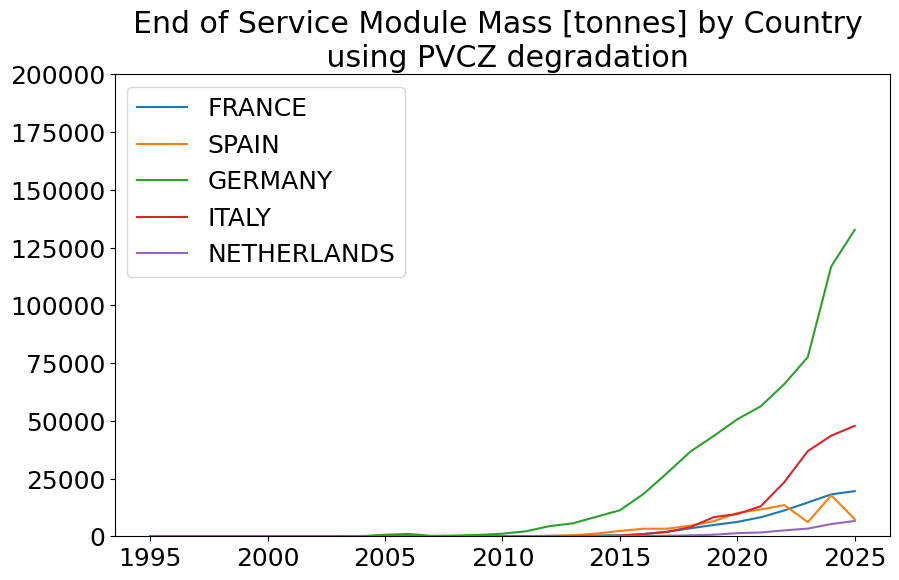

In [83]:
plt.plot(EU_PVCZ_modulemassEoL)
plt.legend(countries)
plt.ylim(0,200000)
plt.title('End of Service Module Mass [tonnes] by Country \n using PVCZ degradation')

In [ ]:
sim2_annual.groupby(func=np.sum, axis

In [ ]:
df_WasteEOL_allFleetsDegscen = pd.DataFrame(sim2_cumu.filter(like='WasteEOL_Module').sum(axis=1)).loc[:2050]
df_WasteEOL_allFleetsDegscen.columns=['WasteEOL_Module_[tonnes]']

In [ ]:
eol_cumu_all = sim1_cumu.filter(like='WasteEOL')
eol_cumu_all_mats_2050 = eol_cumu_all.loc[:2050].iloc[:,:7]
#eol_cumu_all_mats_2050

In [ ]:
eol_cumu_all_mats_2050.columns

In [ ]:
for mat in eol_cumu_all_mats_2050.columns:
    plt.bar(eol_cumu_all_mats_2050.index, eol_cumu_all_mats_2050[mat]/1e6)
plt.legend(MATERIALS)
plt.ylabel('EoL materials \n [million metric tonnes]')
plt.title('Cumulative Mass of EoL materials')
plt.ylim(0,35)
plt.xlim(2000,2051)

In [ ]:
eos_cumu_mats_milltonne = eol_cumu_all_mats_2050/1e6
eos_cumu_mats_milltonne.to_csv(os.path.join(testfolder, 'output_cumu_mats_milltonne.csv'))

## in number of modules and GWs

In [ ]:
sim1.scenario['base'].dataOut_m.keys()

In [ ]:
modulearea_eol_millionm2 = sim1.scenario['base'].dataOut_m['Yearly_Sum_Area_atEOL'].cumsum()/1e6

In [ ]:
plt.bar(sim1.scenario['base'].dataIn_m['year'], modulearea_eol_millionm2)
plt.ylim(0,)
plt.title('Cumulative Area at EoL in 1e6 m2')
plt.ylabel('million meters^2')

In [ ]:
eol_modules_smaller = sim1.scenario['base'].dataOut_m['Yearly_Sum_Area_atEOL'].cumsum()/1.6
eol_modules_larger = sim1.scenario['base'].dataOut_m['Yearly_Sum_Area_atEOL'].cumsum()/2.75
df_modules = pd.concat([eol_modules_smaller, eol_modules_larger], axis=1)
#, columns=
df_modules.columns = ['Cumulative Modules 1.6m2','Cumulative Modules 2.75m2']
df_modules.index = sim1.scenario['base'].dataIn_m['year']
df_modules

In [ ]:
cumu_power_eol = pd.Series(sim1.scenario['base'].dataOut_m['Yearly_Sum_Power_atEOL'].cumsum()/1e9)#GW
cumu_power_eol.index = sim1.scenario['base'].dataIn_m['year']
df_modules['Cumulative Power at EoL [GW]'] = cumu_power_eol

In [ ]:
df_modules.to_csv(os.path.join(testfolder, 'output_modules_power_cumuEoL.csv'))

In [ ]:
plt.plot(df_WasteEOL_allFleetsDegscen/1e6)
plt.ylim(0,700)
plt.xlim(2000,2050)
plt.title('Cumulative End of Service Mass, Fleets Deg.')
plt.ylabel('EoS Module mass\n[Million Metric tonnes]')

In [ ]:
sim2_EoS_mats_cumu_mass = pd.DataFrame()
for mats in MATERIALS:
    sim2_EoS_mats_cumu_mass[mats+'_millionMetricTonne'] = sim2_cumu.filter(regex='WasteEOL_'+mats).sum(axis=1).loc[:2050]/1e6

#sim2_EoS_mats_cumu_mass.tail()

In [ ]:
df_WasteEOL_allFleetsDegscen_MMT = df_WasteEOL_allFleetsDegscen/1e6
df_WasteEOL_allFleetsDegscen_MMT.columns=['WasteEOL_Module_[million metric tonnes]']
df_WasteEOS_allFleetsDeg_Mats_MMT = pd.concat([df_WasteEOL_allFleetsDegscen_MMT, sim2_EoS_mats_cumu_mass], axis=1)
df_WasteEOS_allFleetsDeg_Mats_MMT.to_csv(os.path.join(testfolder, 'output_PVFleetsDeg_cumu_mass_mats_MMT.csv'))

In [ ]:
df_areaEOS_sim2 = pd.DataFrame()
for scen in sim2.scenario.keys():
    df_areaEOS_sim2[scen] = sim2.scenario[scen].dataOut_m['Yearly_Sum_Area_atEOL']

In [ ]:
df_areaEOS_sim2_all = df_areaEOS_sim2.sum(axis=1).cumsum() #sum the scens together, then cumulative area
df_areaEOS_cumu_smallModule = df_areaEOS_sim2_all/1.6
df_areaEOS_cumu_largeModule = df_areaEOS_sim2_all/2.75

df_ModulesEOS_sim2 = pd.concat([df_areaEOS_cumu_smallModule, df_areaEOS_cumu_largeModule],axis=1)
df_ModulesEOS_sim2.columns = ['Cumulative Modules 1.6m2','Cumulative Modules 2.75m2']
df_ModulesEOS_sim2.index = sim1.scenario['base'].dataIn_m['year']
df_ModulesEOS_sim2

In [ ]:
df_powerEOS_sim2 = pd.DataFrame()
for scen in sim2.scenario.keys():
    df_powerEOS_sim2[scen] = sim2.scenario[scen].dataOut_m['Yearly_Sum_Power_atEOL']

In [ ]:
cumu_power_eos_sim2 = pd.Series(df_powerEOS_sim2.sum(axis=1).cumsum()/1e9) #sum the scens together, then cumulative power, in GW
cumu_power_eos_sim2.index = sim1.scenario['base'].dataIn_m['year']
cumu_power_eos_sim2

In [ ]:
df_ModulesEOS_sim2['Cumulative Power at EoS PVFleets [GW]'] = cumu_power_eos_sim2

In [ ]:
df_ModulesEOS_sim2.loc[:2050,].to_csv(os.path.join(testfolder, 'output_PVFleetsDeg_cumu_modulesAndPower.csv'))